# Notebook 2: Train Baselines

This notebook trains the baseline classification models using the prepared datasets from Notebook 1. It establishes the standard supervised-learning performance that will be used as a reference point for the later out-of-distribution (OOD) and abstention experiments.

The workflow loads the training, validation, and test data, configures the model and training settings, and trains the baseline models using the selected features and class labels. During training, loss and performance metrics are monitored on the validation data to compare model behavior and identify the best-performing checkpoints.

After training, the models are evaluated on held-out data and the results are reported using metrics such as accuracy, loss, and class-level performance. The trained models, predictions, and evaluation outputs provide the foundation for measuring how effectively later methods detect uncertainty and decide when a model should abstain from making a prediction.

## Import Libraries

In [1]:
from pathlib import Path
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torch.utils.data import Dataset, DataLoader

from torchvision import transforms
from torchvision.models import (
    mobilenet_v3_small, MobileNet_V3_Small_Weights,
    efficientnet_b0, EfficientNet_B0_Weights,
)

from PIL import Image

from sklearn.metrics import accuracy_score, f1_score, classification_report

In [2]:
FIGURE_DIR = Path("./results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
SEEDS = [14, 27, 42]
BATCH_SIZE = 64

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    if torch.backends.mps.is_available():
        torch.mps.manual_seed(seed)


In [4]:
# Ensures it uses the correct hardware device
if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

print("Device:", device)

Device: mps


## Load Data

In [5]:
SPLIT_DIR = Path("./splits")

train_id = pd.read_csv(SPLIT_DIR / "train_id.csv")
val_id = pd.read_csv(SPLIT_DIR / "val_id.csv")
test_id = pd.read_csv(SPLIT_DIR / "test_id.csv")

with open(SPLIT_DIR / "class_to_idx.json", "r") as f:
    class_to_idx = json.load(f)

idx_to_class = {
    idx: class_name
    for class_name, idx in class_to_idx.items()
}

NUM_CLASSES = len(class_to_idx)

print(f"Train: {len(train_id):,}")
print(f"Val:   {len(val_id):,}")
print(f"Test:  {len(test_id):,}")
print(f"Classes: {NUM_CLASSES}")

Train: 33,508
Val:   3,724
Test:  9,159
Classes: 30


## Curate Dataset for Training

- Defines a Pytorch Dataset
- Defines normalisation and augmentation functions
- Creates dataloaders

In [6]:
# Define Pytorch Dataset
class PlantVillageDataset(Dataset):
    def __init__(self, dataframe, class_to_idx, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.class_to_idx = class_to_idx
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")

        label = self.class_to_idx[row["class_name"]]

        if self.transform is not None:
            image = self.transform(image)

        return image, label

In [7]:
### Both EfficientNetB0 and MobileNetV3 expect 3 color channels and 224x224 dimensions
# Normalisation transformation

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])

In [8]:
# Create dataset objects for each split
train_dataset = PlantVillageDataset(
    train_id,
    class_to_idx,
    transform=transform,
)

val_dataset = PlantVillageDataset(
    val_id,
    class_to_idx,
    transform=transform,
)

test_dataset = PlantVillageDataset(
    test_id,
    class_to_idx,
    transform=transform,
)

In [9]:
def make_loaders(seed):
    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )

    return train_loader, val_loader, test_loader

## Model Factory

In [10]:
# Define resuable function to create a model and establish transfer learning
def create_model(model_name, num_classes):
    if model_name == "mobilenet_v3_small":
        # Load pre-trained model
        weights = MobileNet_V3_Small_Weights.DEFAULT
        model = mobilenet_v3_small(weights=weights)

        # Replace the final layer
        model.classifier[3] = nn.Linear(
            model.classifier[3].in_features,
            num_classes,
        )

    elif model_name == "efficientnet_b0":
        # Load pre-trained model
        weights = EfficientNet_B0_Weights.DEFAULT
        model = efficientnet_b0(weights=weights)

        # Replace the final layer
        model.classifier[1] = nn.Linear(
            model.classifier[1].in_features,
            num_classes,
        )

    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model

## Training and Validation Functions

In [11]:
def train_one_epoch(
    model,
    loader,
    optimizer,
    criterion,
    device,
):
    model.train()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(images)

        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc = accuracy_score(all_labels, all_preds)

    return epoch_loss, epoch_acc

@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion,
    device,
):
    model.eval()

    running_loss = 0.0
    all_preds = []
    all_labels = []

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        logits = model(images)

        loss = criterion(logits, labels)

        running_loss += loss.item() * images.size(0)

        preds = logits.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    epoch_loss = running_loss / len(loader.dataset)

    acc = accuracy_score(
        all_labels,
        all_preds,
    )

    macro_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
    )

    return epoch_loss, acc, macro_f1

## Training Configuration

In [12]:
LEARNING_RATE = 1e-4
MAX_EPOCHS = 12
PATIENCE = 3

criterion = nn.CrossEntropyLoss()

## Generic Training Function

In [13]:
def train_model(
    model,
    model_name,
    train_loader,
    val_loader,
    device,
    max_epochs=15,
    patience=5,
    learning_rate=1e-4,
):
    criterion = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate,
    )

    history = []

    best_val_loss = float("inf")
    best_state = None
    patience_counter = 0

    start_time = time.time()

    for epoch in range(max_epochs):

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            optimizer,
            criterion,
            device,
        )

        val_loss, val_acc, val_f1 = evaluate(
            model,
            val_loader,
            criterion,
            device,
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "val_macro_f1": val_f1,
        })

        print(
            f"{model_name} | "
            f"Epoch {epoch + 1:02d} | "
            f"Train loss {train_loss:.4f} | "
            f"Train acc {train_acc:.4f} | "
            f"Val loss {val_loss:.4f} | "
            f"Val acc {val_acc:.4f} | "
            f"Val F1 {val_f1:.4f}"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= patience:
            print("Early stopping.")
            break

    training_time = time.time() - start_time

    model.load_state_dict(best_state)

    return model, pd.DataFrame(history), training_time

# Seeded baseline training

Each baseline model is trained independently with seeds 14, 27, and 42. The data-loader shuffle order, model initialisation, training history, checkpoints, and evaluation metadata are stored separately for each seed.

In [14]:
MODEL_DIR = Path("./models")
RESULT_DIR = Path("./results")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_NAMES = {
    "mobilenet_v3_small": "MobileNetV3-Small",
    "efficientnet_b0": "EfficientNet-B0",
}


def train_and_evaluate(model_name, seed):
    set_seed(seed)
    train_loader, val_loader, test_loader = make_loaders(seed)

    model = create_model(model_name, NUM_CLASSES).to(device)
    model, history, training_time = train_model(
        model,
        MODEL_NAMES[model_name],
        train_loader,
        val_loader,
        device,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE,
        learning_rate=LEARNING_RATE,
    )

    test_loss, test_acc, test_f1 = evaluate(
        model,
        test_loader,
        nn.CrossEntropyLoss(),
        device,
    )

    checkpoint_path = MODEL_DIR / f"{model_name}_seed{seed}.pt"
    history_path = RESULT_DIR / f"{model_name}_history_seed{seed}.csv"
    metadata_path = RESULT_DIR / f"{model_name}_metadata_seed{seed}.json"

    torch.save(model.state_dict(), checkpoint_path)
    history.to_csv(history_path, index=False)

    metadata = {
        "model": model_name,
        "seed": seed,
        "num_classes": NUM_CLASSES,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "optimizer": "Adam",
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "training_time_seconds": training_time,
        "test_loss": test_loss,
        "test_accuracy": test_acc,
        "test_macro_f1": test_f1,
        "checkpoint": str(checkpoint_path),
        "history": str(history_path),
    }

    with open(metadata_path, "w") as f:
        json.dump(metadata, f, indent=2)

    print(
        f"{MODEL_NAMES[model_name]} | seed={seed} | "
        f"Test loss={test_loss:.4f} | "
        f"Test accuracy={test_acc:.4f} | "
        f"Test Macro F1={test_f1:.4f}"
    )

    return metadata, history


all_results = []
all_histories = {}

for seed in SEEDS:
    for model_name in MODEL_NAMES:
        metadata, history = train_and_evaluate(model_name, seed)
        all_results.append(metadata)
        all_histories[(model_name, seed)] = history

baseline_seeded_summary = pd.DataFrame(all_results)
baseline_seeded_summary.to_csv(
    RESULT_DIR / "baseline_seeded_summary.csv",
    index=False,
)

baseline_seeded_summary[[
    "model",
    "seed",
    "test_loss",
    "test_accuracy",
    "test_macro_f1",
]]

MobileNetV3-Small | Epoch 01 | Train loss 0.5988 | Train acc 0.8505 | Val loss 0.0881 | Val acc 0.9750 | Val F1 0.9702
MobileNetV3-Small | Epoch 02 | Train loss 0.0612 | Train acc 0.9823 | Val loss 0.0462 | Val acc 0.9866 | Val F1 0.9846
MobileNetV3-Small | Epoch 03 | Train loss 0.0280 | Train acc 0.9919 | Val loss 0.0323 | Val acc 0.9890 | Val F1 0.9852
MobileNetV3-Small | Epoch 04 | Train loss 0.0141 | Train acc 0.9961 | Val loss 0.0208 | Val acc 0.9919 | Val F1 0.9849
MobileNetV3-Small | Epoch 05 | Train loss 0.0101 | Train acc 0.9975 | Val loss 0.0274 | Val acc 0.9914 | Val F1 0.9885
MobileNetV3-Small | Epoch 06 | Train loss 0.0081 | Train acc 0.9976 | Val loss 0.0369 | Val acc 0.9885 | Val F1 0.9839
MobileNetV3-Small | Epoch 07 | Train loss 0.0060 | Train acc 0.9984 | Val loss 0.0136 | Val acc 0.9960 | Val F1 0.9940
MobileNetV3-Small | Epoch 08 | Train loss 0.0056 | Train acc 0.9984 | Val loss 0.0214 | Val acc 0.9936 | Val F1 0.9916
MobileNetV3-Small | Epoch 09 | Train loss 0.0034

,model,seed,test_loss,test_accuracy,test_macro_f1
0,mobilenet_v3_small,14,0.036464,0.989300,0.986417
1,efficientnet_b0,14,0.021744,0.993995,0.992188
2,mobilenet_v3_small,27,0.025631,0.992576,0.990688
3,efficientnet_b0,27,0.017434,0.995196,0.993867
4,mobilenet_v3_small,42,0.030771,0.992139,0.990306
5,efficientnet_b0,42,0.013727,0.995524,0.994130


## Seed-specific training curves

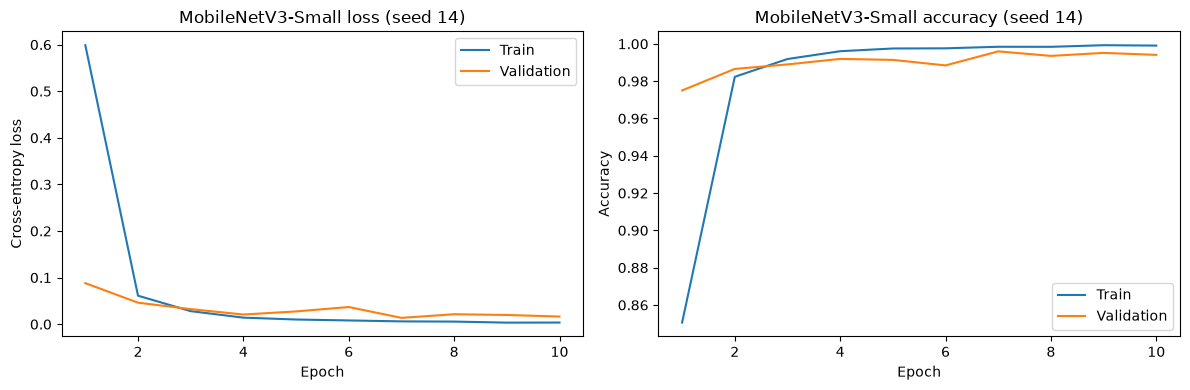

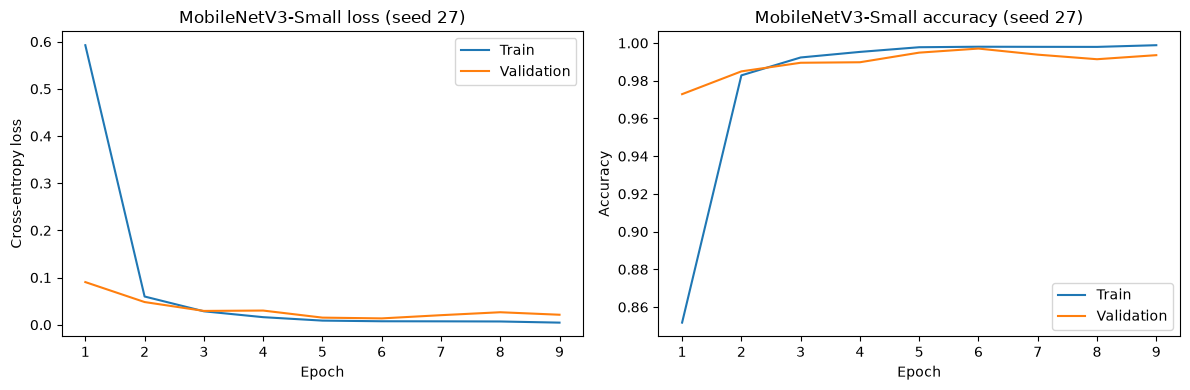

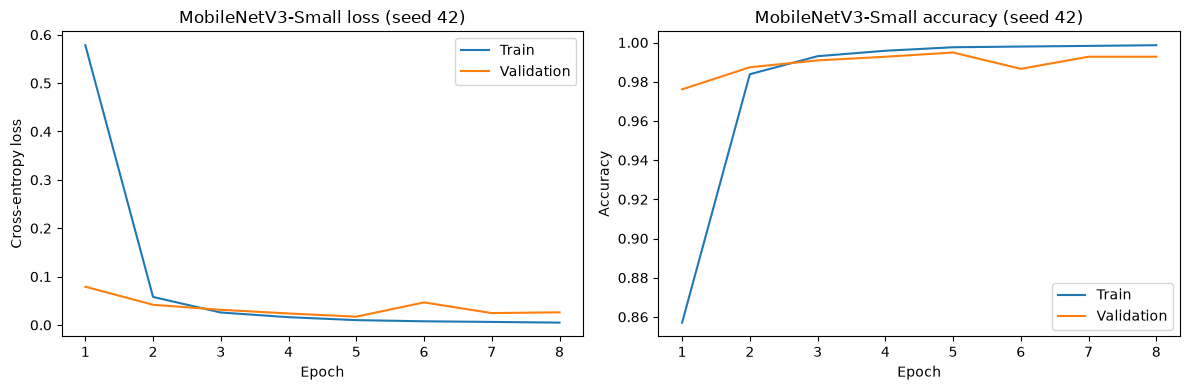

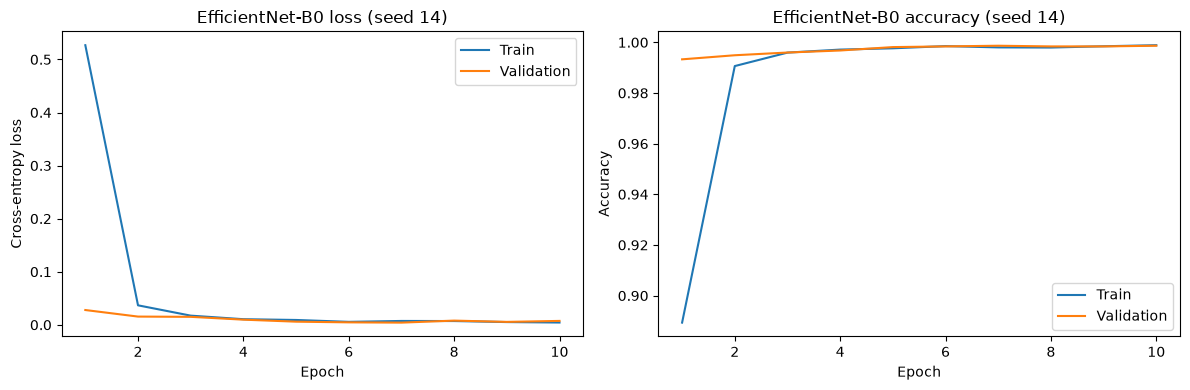

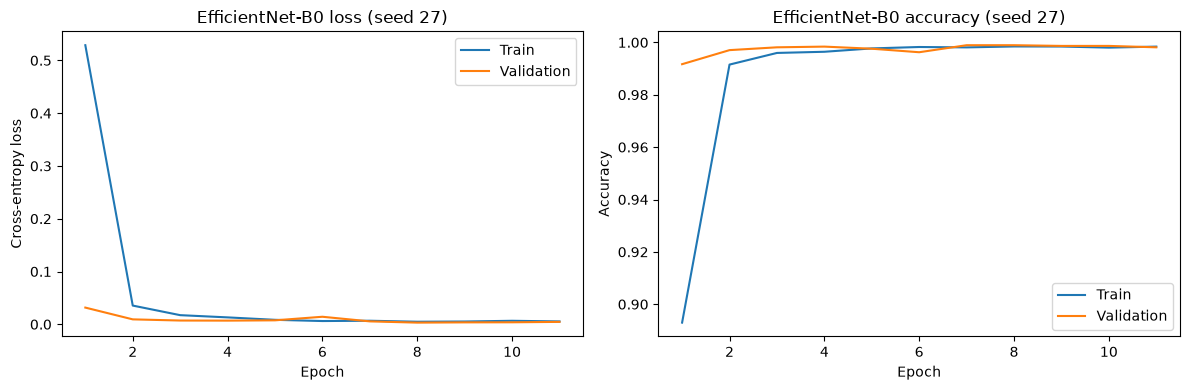

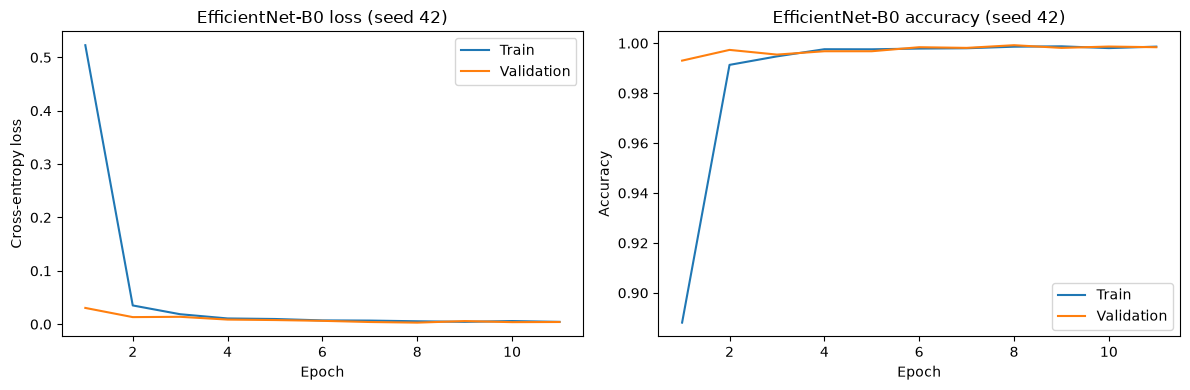

In [15]:
for model_name, display_name in MODEL_NAMES.items():
    for seed in SEEDS:
        history = all_histories[(model_name, seed)]

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(history["epoch"], history["train_loss"], label="Train")
        axes[0].plot(history["epoch"], history["val_loss"], label="Validation")
        axes[0].set_title(f"{display_name} loss (seed {seed})")
        axes[0].set_xlabel("Epoch")
        axes[0].set_ylabel("Cross-entropy loss")
        axes[0].legend()

        axes[1].plot(history["epoch"], history["train_acc"], label="Train")
        axes[1].plot(history["epoch"], history["val_acc"], label="Validation")
        axes[1].set_title(f"{display_name} accuracy (seed {seed})")
        axes[1].set_xlabel("Epoch")
        axes[1].set_ylabel("Accuracy")
        axes[1].legend()

        fig.tight_layout()
        fig.savefig(
            FIGURE_DIR / f"{model_name}_training_curves_seed{seed}.png",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()